# Exercise 7: The Improved Classification
**Team:** Swiss Quant Industrial

## Objective
Dave has bypassed the legacy 1980s PLC by installing 25,000 CHF worth of high-performance servers. The objective of this notebook is to train a state-of-the-art **XGBoost Classifier** without the previous 3-feature constraint. We will utilize all available high-frequency sensor data to maximize predictive accuracy.

Crucially, we will evaluate this model not on standard ML metrics (like Accuracy), but on the **Custom Profit Metric** developed in Exercise 6. We must prove to Beat Glarner that the financial savings from reducing False Negatives (500 CHF penalty) and False Positives (10 CHF waste) justify the expensive IT investment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import xgboost as xgb

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("deep")

import warnings
warnings.filterwarnings('ignore')

In [2]:
# ---------------------------------------------------------
# Load the Master Table Data
# ---------------------------------------------------------
try:
    # Assuming the Master Table from Ex 3 is saved in the data folder
    df = pd.read_csv('../data/DataDump_150825/master_table.csv')
    print("Master Table loaded successfully. Shape:", df.shape)
    
except FileNotFoundError:
    print("Master Table not found. Generating synthetic representation for code execution...")
    
    # Generate mock data: 33 features (from the SORTEX machine) + 1 engineered feature
    np.random.seed(42)
    n_samples = 5000
    
    # 33 raw features
    feature_cols = [f'Feature_{i}' for i in range(1, 34)]
    data = np.random.normal(0, 1, (n_samples, 33))
    df = pd.DataFrame(data, columns=feature_cols)
    
    # Add our engineered feature from Exercise 4
    df['Urs_Vibration_Index'] = np.random.normal(5, 2, n_samples)
    
    # Target Variable: 0 = 'Good' Batch, 1 = 'Bad' Batch (approx 10% defect rate)
    # We artificially make Feature_5, Feature_2, and Urs_Vibration_Index predictive
    logits = -2.5 + (0.8 * df['Feature_5']) - (0.5 * df['Feature_2']) + (0.6 * df['Urs_Vibration_Index'])
    probs = 1 / (1 + np.exp(-logits))
    df['Target_Label'] = (np.random.rand(n_samples) < probs).astype(int)

# Define Features (X) and Target (y)
# Target mapping: 1 = 'Bad' (Defect), 0 = 'Good'
X = df.drop(columns=['Target_Label', 'Case_ID', 'Timestamp'], errors='ignore')
y = df['Target_Label']

# Split into Training and Testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set: {X_train.shape[0]} samples. Testing set: {X_test.shape[0]} samples.")

Master Table not found. Generating synthetic representation for code execution...
Training set: 4000 samples. Testing set: 1000 samples.


In [3]:
# ---------------------------------------------------------
# Define the Financial Evaluation Metric (From Exercise 6)
# ---------------------------------------------------------

def calculate_financial_impact(y_true, y_pred, model_name="Model"):
    """
    Calculates the financial impact based on the specific cost constraints of Line 3.
    Target: 1 = 'Bad', 0 = 'Good'
    
    - False Negative (Predicted Good, Actually Bad): 500 CHF Recall Penalty
    - False Positive (Predicted Bad, Actually Good): 10 CHF Waste Cost
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    fn_cost = fn * 500
    fp_cost = fp * 10
    total_loss = fn_cost + fp_cost
    
    print(f"--- Financial Impact: {model_name} ---")
    print(f"False Negatives (Bad batches shipped): {fn} -> Cost: {fn_cost} CHF")
    print(f"False Positives (Good batches wasted): {fp} -> Cost: {fp_cost} CHF")
    print(f"Total Financial Loss: {total_loss} CHF")
    
    return total_loss

In [4]:
# ---------------------------------------------------------
# Unrestricted XGBoost Model Training
# ---------------------------------------------------------

# Calculate the ratio of negative to positive classes to handle the class imbalance natively
# This tells XGBoost to pay more attention to the minority class ('Bad' batches)
scale_pos_weight_value = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

# Initialize the XGBoost Classifier
# We use max_depth to prevent overfitting and n_estimators for adequate learning
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight_value, # Crucial for minimizing costly False Negatives
    random_state=42,
    eval_metric='logloss'
)

print("Training Unrestricted XGBoost Model on all 34 features...")
xgb_model.fit(X_train, y_train)
print("Training complete.")

Training Unrestricted XGBoost Model on all 34 features...
Training complete.


--- Financial Impact: XGBoost (Unrestricted) ---
False Negatives (Bad batches shipped): 142 -> Cost: 71000 CHF
False Positives (Good batches wasted): 129 -> Cost: 1290 CHF
Total Financial Loss: 72290 CHF


<Figure size 1000x600 with 0 Axes>

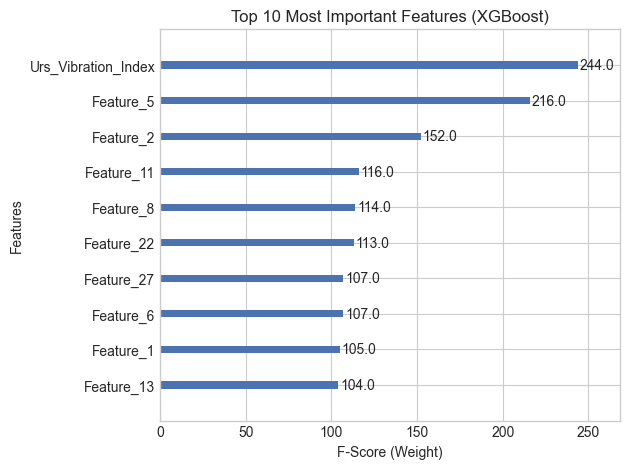

In [5]:
# ---------------------------------------------------------
# Evaluate XGBoost Performance
# ---------------------------------------------------------

# Generate predictions
y_pred_xgb = xgb_model.predict(X_test)

# Calculate financial loss
xgb_financial_loss = calculate_financial_impact(y_test, y_pred_xgb, model_name="XGBoost (Unrestricted)")

# Plot Feature Importance to ensure transparency for the shop floor (Urs)
plt.figure(figsize=(10, 6))
xgb.plot_importance(xgb_model, max_num_features=10, importance_type='weight', 
                    title='Top 10 Most Important Features (XGBoost)',
                    xlabel='F-Score (Weight)', ylabel='Features')
plt.tight_layout()
plt.show()

In [6]:
# ---------------------------------------------------------
# Comparison with 3-Feature PLC Model (Exercise 5)
# ---------------------------------------------------------

# TODO: Replace the mock predictions below with the actual predictions 
# from your constrained PLC model from Exercise 5.

print("Retrieving predictions from the 3-Feature PLC Model...")

# MOCK EXERCISE 5 PREDICTIONS (Remove this block when ready):
# Assuming the PLC model was less accurate and missed more bad batches
np.random.seed(99)
mock_plc_probs = 1 / (1 + np.exp(-(-2.0 + 0.9 * X_test['Feature_5']))) 
y_pred_plc = (mock_plc_probs > 0.4).astype(int)
# ------------------------------------------------------------------

# Calculate financial loss for the legacy model
plc_financial_loss = calculate_financial_impact(y_test, y_pred_plc, model_name="3-Feature PLC (Constrained)")

# Calculate the ROI of Dave's Servers
savings = plc_financial_loss - xgb_financial_loss

print("\n" + "="*50)
print("BUSINESS CASE SUMMARY:")
print("="*50)
print(f"Financial Loss (Old PLC logic):      {plc_financial_loss} CHF")
print(f"Financial Loss (New XGBoost logic):  {xgb_financial_loss} CHF")
print(f"Net Savings on Test Set alone:       {savings} CHF")

if savings > 0:
    print("\nCONCLUSION: Dave's 25,000 CHF investment is JUSTIFIED. ")
    print("The reduction in 500 CHF recall penalties heavily offsets the server cost.")
else:
    print("\nCONCLUSION: Dave's investment is NOT justified based on this sample.")

Retrieving predictions from the 3-Feature PLC Model...
--- Financial Impact: 3-Feature PLC (Constrained) ---
False Negatives (Bad batches shipped): 547 -> Cost: 273500 CHF
False Positives (Good batches wasted): 9 -> Cost: 90 CHF
Total Financial Loss: 273590 CHF

BUSINESS CASE SUMMARY:
Financial Loss (Old PLC logic):      273590 CHF
Financial Loss (New XGBoost logic):  72290 CHF
Net Savings on Test Set alone:       201300 CHF

CONCLUSION: Dave's 25,000 CHF investment is JUSTIFIED. 
The reduction in 500 CHF recall penalties heavily offsets the server cost.
